/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


[Vol. 3 (Homogeneous)] Loaded: AgentSyncModelVol.3_TempoShift_Fixed-table.csv (157.96 MB | Modified: 2026-11-27 14:38:41)
[Vol. 4 (Heterogeneous)] Loaded: AgentSyncModelVol.4_TempoShift-table.csv (142.19 MB | Modified: 2026-11-27 13:58:13)

ANALYSIS: VOL. 3 (HOMOGENEOUS)
--- Descriptive Statistics (Recovery Ticks Post-Shift) ---
          N    Mean      SD  Median   IQR  Min   Max
weight                                              
0.2     100  328.46  562.76   265.0   6.0  254  5835
0.5     100  721.75   37.57   710.5  26.5  680   869
0.8     100  533.21   10.11   532.0  12.5  514   564
Total runs: 300 | Unrecovered runs (NaN): 0

--- Normality Check (Shapiro-Wilk) ---
  w = 0.2: W = 0.0974, p = 5.6902e-22
  w = 0.5: W = 0.7745, p = 4.3765e-11
  w = 0.8: W = 0.9715, p = 2.9076e-02

--- Omnibus Inferential Tests Across Coupling Weights ---
  Kruskal-Wallis: H = 250.2148, p = 4.6403e-55, epsilon^2 = 0.8368
  One-Way ANOVA:  F = 36.4762, p = 6.8341e-15, eta^2 = 0.1972

--- Post-Hoc Pair

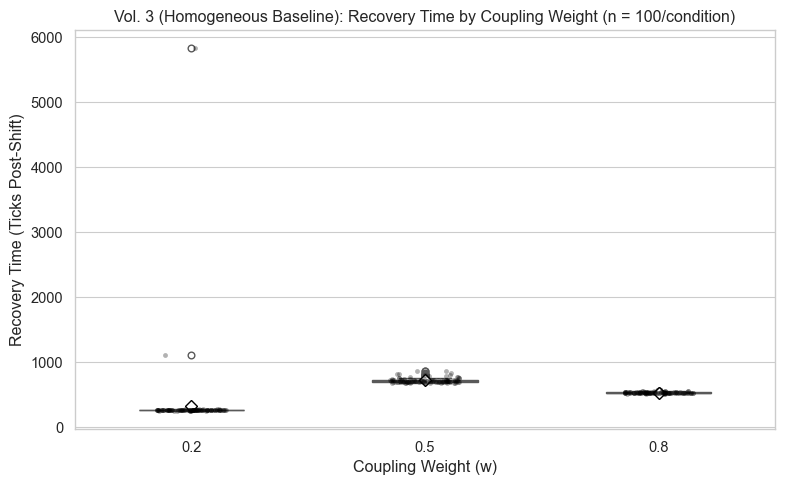

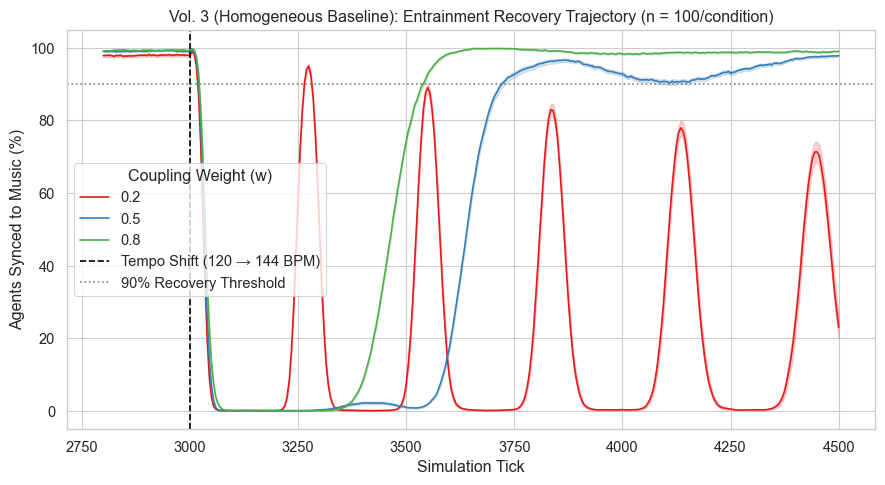

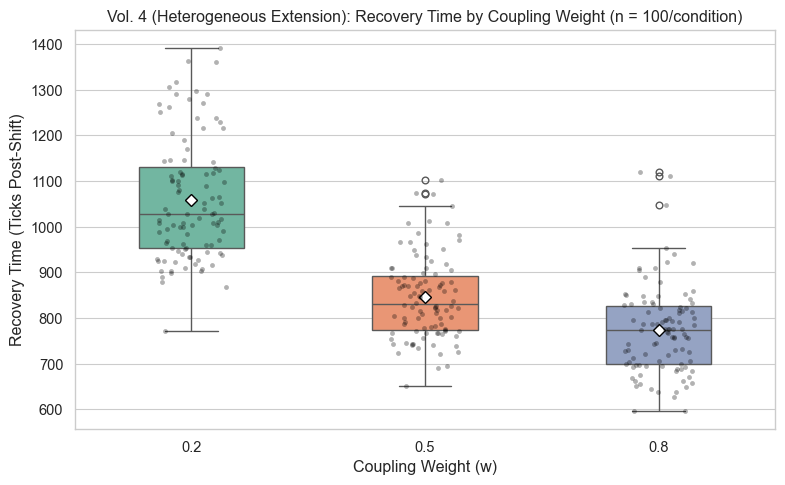

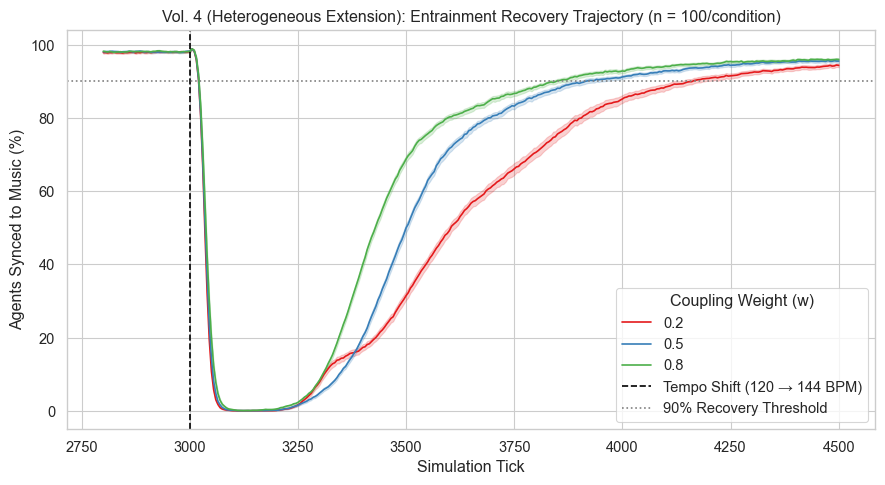

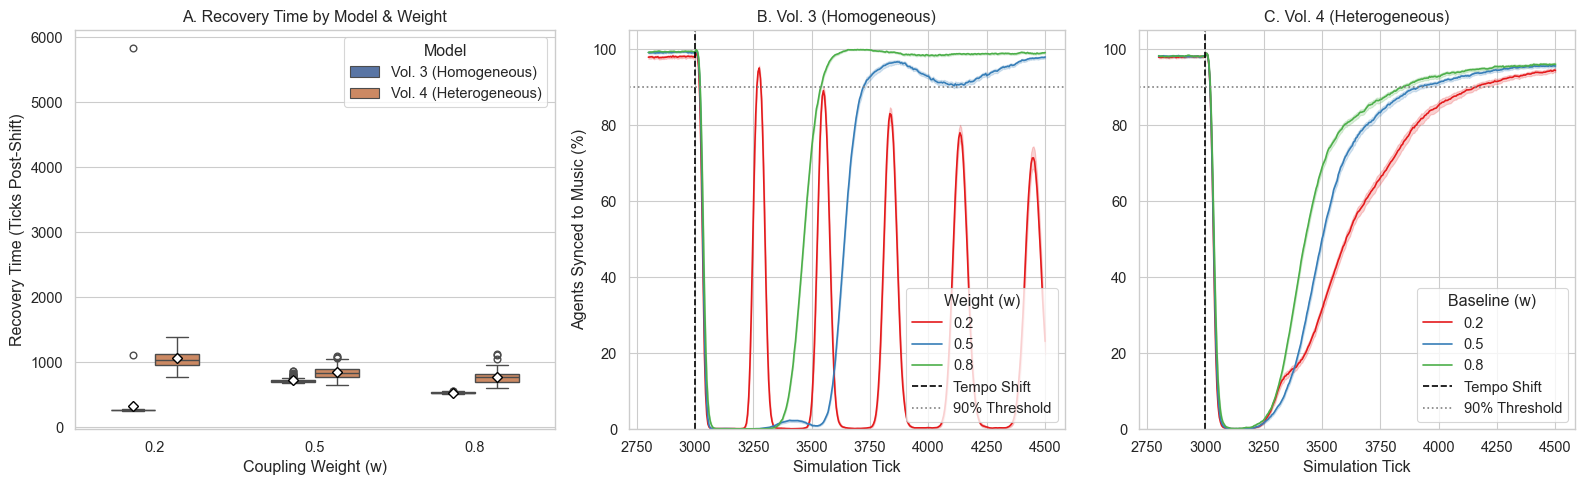

In [1]:
import os
import csv
import glob
from datetime import datetime
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt

# ==============================================================================
# 1. CONFIGURATION & FILE DISCOVERY
# ==============================================================================
WORK_DIR = "/Users/rutgersmac/Library/CloudStorage/OneDrive-TilburgUniversity/CSAI/Year 2/Y2 S1/Multi-Agent Systems/new project/WD_Experiments_Analysis"

# Leave as None to automatically pick the newest Vol. 3 and Vol. 4 CSVs in WORK_DIR,
# or set exact filenames (e.g., "AgentSyncModelVol.3_TempoShift_Fixed-table.csv")
VOL3_FILENAME = None
VOL4_FILENAME = None


def find_latest_model_csv(work_dir, patterns, explicit_name=None):
    """Locate the most recently modified BehaviorSpace CSV matching given patterns."""
    if explicit_name:
        path = os.path.join(work_dir, explicit_name)
        if not os.path.exists(path):
            raise FileNotFoundError(f"Specified file not found: {path}")
        return path

    candidates = []
    for pat in patterns:
        candidates.extend(glob.glob(os.path.join(work_dir, pat)))

    # Exclude any summary CSVs generated by this script
    candidates = [
        p for p in set(candidates)
        if not os.path.basename(p).startswith("summary_")
    ]
    if not candidates:
        raise FileNotFoundError(
            f"No CSV matching {patterns} found in {work_dir}. "
            "Set VOL3_FILENAME / VOL4_FILENAME manually at the top of the script."
        )
    return max(candidates, key=os.path.getmtime)


# ==============================================================================
# 2. DATA LOADER & RECOVERY TIME EXTRACTION (SUPPORTS TABLE & SPREADSHEET CSV)
# ==============================================================================
def analyze_experiment_csv(csv_path, model_name):
    """Load a NetLogo BehaviorSpace export, verify runtime w, and compute recovery times."""
    mod_time = datetime.fromtimestamp(os.path.getmtime(csv_path)).strftime("%Y-%m-%d %H:%M:%S")
    size_mb = os.path.getsize(csv_path) / (1024 ** 2)
    print(f"[{model_name}] Loaded: {os.path.basename(csv_path)} ({size_mb:.2f} MB | Modified: {mod_time})")

    meta_rows = []
    with open(csv_path, "r", encoding="utf-8", errors="ignore", newline="") as f:
        reader = csv.reader(f)
        for _ in range(35):
            try:
                meta_rows.append(next(reader))
            except StopIteration:
                break

    row_labels = [r[0].strip() if len(r) > 0 else "" for r in meta_rows]
    if "[run number]" not in row_labels:
        raise ValueError(f"Could not find '[run number]' header in {csv_path}")

    run_row_idx = row_labels.index("[run number]")
    header_cols = [c.strip() for c in meta_rows[run_row_idx]]
    is_table_format = "[step]" in header_cols

    if is_table_format:
        sync_matches = [c for c in header_cols if "wrap-error" in c and "100" in c]
        if not sync_matches:
            raise ValueError(f"Could not locate '% synced' reporter column in {csv_path}")
        sync_col = sync_matches[0]

        # Handle both standard 'w' and duplicate 'w.1' (when 'w' is also logged as a reporter)
        target_names = {"[run number]", "w", "w.1", "[step]", sync_col}
        post_chunks, vis_chunks = [], []

        for chunk in pd.read_csv(
            csv_path,
            skiprows=run_row_idx,
            usecols=lambda c: c.strip() in target_names,
            chunksize=500_000,
        ):
            chunk.columns = chunk.columns.str.strip()
            rename_map = {
                "[run number]": "run_id",
                "w": "weight",
                "[step]": "tick",
                sync_col: "pct_synced",
            }
            if "w.1" in chunk.columns:
                rename_map["w.1"] = "w_reported"
            chunk = chunk.rename(columns=rename_map)

            post_chunks.append(chunk[chunk["tick"] > 3000])
            vis_chunks.append(
                chunk[(chunk["tick"] >= 2800) & (chunk["tick"] <= 4500) & (chunk["tick"] % 5 == 0)]
            )

        df_post = pd.concat(post_chunks, ignore_index=True)
        df_vis = pd.concat(vis_chunks, ignore_index=True)

        # Verify that runtime slider w matched BehaviorSpace condition w
        if "w_reported" in df_post.columns:
            matches = np.allclose(df_post["weight"], df_post["w_reported"], atol=1e-6)
            print(f"[{model_name}] Runtime slider verification (w == w_reported): {matches}")

        records = []
        for (w_val, r_id), group in df_post.groupby(["weight", "run_id"], sort=False):
            min_sync = group["pct_synced"].min()
            nadir_tick = group.loc[group["pct_synced"] == min_sync, "tick"].min()
            rec_points = group[(group["tick"] > nadir_tick) & (group["pct_synced"] >= 90)]
            rec_ticks = np.nan if rec_points.empty else (rec_points["tick"].iloc[0] - 3000)
            records.append({
                "model": model_name,
                "weight": float(w_val),
                "run_id": int(r_id),
                "recovery_ticks": rec_ticks,
            })

        recovery_df = pd.DataFrame(records)
        df_vis = df_vis[["tick", "weight", "pct_synced"]].copy()
        df_vis["model"] = model_name

    else:
        w_row_idx = row_labels.index("w")
        all_data_idx = row_labels.index("[all run data]")
        rep_row_idx = row_labels.index("[reporter]") if "[reporter]" in row_labels else None

        run_row = meta_rows[run_row_idx]
        w_row = meta_rows[w_row_idx]
        rep_row = meta_rows[rep_row_idx] if rep_row_idx is not None else []
        max_cols = max(len(r) for r in meta_rows)

        target_cols, col_meta = [], {}
        curr_run, curr_w = None, None
        for col_idx in range(1, max_cols):
            r_str = run_row[col_idx].strip() if col_idx < len(run_row) else ""
            if r_str != "":
                curr_run = int(float(r_str))
            if col_idx < len(w_row) and w_row[col_idx].strip() != "":
                curr_w = float(w_row[col_idx].strip())

            if rep_row_idx is not None:
                rep_str = rep_row[col_idx].strip() if col_idx < len(rep_row) else ""
                if "wrap-error" in rep_str and "100" in rep_str:
                    target_cols.append(col_idx)
                    col_meta[col_idx] = (curr_w, curr_run)
            elif r_str != "":
                target_cols.append(col_idx)
                col_meta[col_idx] = (curr_w, curr_run)

        ts_df = (
            pd.read_csv(csv_path, skiprows=all_data_idx + 1, names=range(max_cols), usecols=target_cols, header=None)
            .apply(pd.to_numeric, errors="coerce")
            .dropna(how="all")
            .reset_index(drop=True)
        )

        records = []
        for col_idx in target_cols:
            w_val, r_id = col_meta[col_idx]
            post = ts_df.loc[ts_df.index > 3000, col_idx]
            min_sync = post.min()
            nadir_tick = post[post == min_sync].index.min()
            rec_points = post[(post.index > nadir_tick) & (post >= 90)]
            rec_ticks = np.nan if rec_points.empty else (rec_points.index[0] - 3000)
            records.append({
                "model": model_name,
                "weight": float(w_val),
                "run_id": int(r_id),
                "recovery_ticks": rec_ticks,
            })

        recovery_df = pd.DataFrame(records)
        vis_slice = ts_df.loc[2800:4500:5, target_cols].copy()
        vis_slice.index.name = "tick"
        df_vis = vis_slice.reset_index().melt(id_vars="tick", var_name="col_idx", value_name="pct_synced")
        df_vis["weight"] = df_vis["col_idx"].map(lambda c: col_meta[c][0])
        df_vis["model"] = model_name
        df_vis = df_vis[["tick", "weight", "pct_synced", "model"]]

    return recovery_df, df_vis


# ==============================================================================
# 3. STATISTICAL REPORTING FUNCTIONS
# ==============================================================================
def run_within_model_stats(recovery_df, model_name):
    """Print descriptive, normality, omnibus, and post-hoc statistics for a single model."""
    print("=" * 78)
    print(f"ANALYSIS: {model_name.upper()}")
    print("=" * 78)

    summary = (
        recovery_df.groupby("weight")["recovery_ticks"]
        .agg(
            N="count",
            Mean="mean",
            SD="std",
            Median="median",
            IQR=lambda x: x.quantile(0.75) - x.quantile(0.25),
            Min="min",
            Max="max",
        )
        .round(2)
    )
    summary["Model"] = model_name

    print("--- Descriptive Statistics (Recovery Ticks Post-Shift) ---")
    print(summary[["N", "Mean", "SD", "Median", "IQR", "Min", "Max"]])
    print(
        f"Total runs: {len(recovery_df)} | "
        f"Unrecovered runs (NaN): {recovery_df['recovery_ticks'].isna().sum()}\n"
    )

    weights = sorted(recovery_df["weight"].unique())
    groups = [recovery_df[recovery_df["weight"] == w]["recovery_ticks"].dropna().values for w in weights]

    print("--- Normality Check (Shapiro-Wilk) ---")
    for w_val, vals in zip(weights, groups):
        w_stat, p_norm = stats.shapiro(vals[:5000])
        print(f"  w = {w_val}: W = {w_stat:.4f}, p = {p_norm:.4e}")

    h_stat, p_kw = stats.kruskal(*groups)
    n_total = sum(len(g) for g in groups)
    eps_sq = h_stat / (n_total - 1)

    f_stat, p_anova = stats.f_oneway(*groups)
    grand_mean = np.concatenate(groups).mean()
    ss_between = sum(len(g) * (g.mean() - grand_mean) ** 2 for g in groups)
    ss_total = sum(((g - grand_mean) ** 2).sum() for g in groups)
    eta_sq = ss_between / ss_total

    print("\n--- Omnibus Inferential Tests Across Coupling Weights ---")
    print(f"  Kruskal-Wallis: H = {h_stat:.4f}, p = {p_kw:.4e}, epsilon^2 = {eps_sq:.4f}")
    print(f"  One-Way ANOVA:  F = {f_stat:.4f}, p = {p_anova:.4e}, eta^2 = {eta_sq:.4f}")

    if p_kw < 0.05:
        print("\n--- Post-Hoc Pairwise Mann-Whitney U (Bonferroni Corrected) ---")
        for i in range(len(weights)):
            for j in range(i + 1, len(weights)):
                u_stat, p_pair = stats.mannwhitneyu(groups[i], groups[j], alternative="two-sided")
                p_adj = min(p_pair * 3, 1.0)
                print(f"  w = {weights[i]} vs w = {weights[j]}: U = {u_stat:.1f}, p_adj = {p_adj:.4e}")
    print()
    return summary.reset_index()


def run_cross_model_comparison(rec_vol3, rec_vol4):
    """Compare Vol. 3 (Homogeneous) vs. Vol. 4 (Heterogeneous) at each weight condition."""
    print("=" * 78)
    print("CROSS-MODEL COMPARISON: VOL. 3 (HOMOGENEOUS) VS. VOL. 4 (HETEROGENEOUS)")
    print("=" * 78)

    shared_weights = sorted(set(rec_vol3["weight"]).intersection(set(rec_vol4["weight"])))
    for w_val in shared_weights:
        g3 = rec_vol3[rec_vol3["weight"] == w_val]["recovery_ticks"].dropna().values
        g4 = rec_vol4[rec_vol4["weight"] == w_val]["recovery_ticks"].dropna().values
        u_stat, p_u = stats.mannwhitneyu(g3, g4, alternative="two-sided")
        t_stat, p_t = stats.ttest_ind(g3, g4, equal_var=False)
        print(
            f"w = {w_val} | Vol. 3 Median={np.median(g3):.1f} (Mean={np.mean(g3):.1f}) vs. "
            f"Vol. 4 Median={np.median(g4):.1f} (Mean={np.mean(g4):.1f}) -> "
            f"Mann-Whitney U={u_stat:.1f} (p={p_u:.4e}), Welch t={t_stat:.2f} (p={p_t:.4e})"
        )
    print()


# ==============================================================================
# 4. EXECUTION & PUBLICATION-READY PLOTS (300 DPI)
# ==============================================================================
vol3_path = find_latest_model_csv(WORK_DIR, ["*Vol.3*.csv", "*Vol3*.csv"], VOL3_FILENAME)
vol4_path = find_latest_model_csv(WORK_DIR, ["*Vol.4*.csv", "*Vol4*.csv"], VOL4_FILENAME)

rec_vol3, vis_vol3 = analyze_experiment_csv(vol3_path, "Vol. 3 (Homogeneous)")
rec_vol4, vis_vol4 = analyze_experiment_csv(vol4_path, "Vol. 4 (Heterogeneous)")
print()

summary_vol3 = run_within_model_stats(rec_vol3, "Vol. 3 (Homogeneous)")
summary_vol4 = run_within_model_stats(rec_vol4, "Vol. 4 (Heterogeneous)")
run_cross_model_comparison(rec_vol3, rec_vol4)

# Export combined descriptive table to CSV for easy insertion into Word
combined_summary = pd.concat([summary_vol3, summary_vol4], ignore_index=True)
combined_summary = combined_summary[["Model", "weight", "N", "Mean", "SD", "Median", "IQR", "Min", "Max"]]
summary_csv_path = os.path.join(WORK_DIR, "summary_vol3_vs_vol4_stats.csv")
combined_summary.to_csv(summary_csv_path, index=False)
print(f"Saved combined summary table to: {summary_csv_path}\n")

# --- Visualizations ---
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)

for tag, rec_df, vis_df, label in [
    ("vol3", rec_vol3, vis_vol3, "Vol. 3 (Homogeneous Baseline)"),
    ("vol4", rec_vol4, vis_vol4, "Vol. 4 (Heterogeneous Extension)"),
]:
    n_per_cond = int(rec_df.groupby("weight")["recovery_ticks"].count().min())

    # 1. Individual Model Boxplot + Mean Diamond + Stripplot
    plt.figure(figsize=(8, 5))
    sns.boxplot(
        data=rec_df,
        x="weight",
        y="recovery_ticks",
        hue="weight",
        palette="Set2",
        width=0.45,
        legend=False,
        showmeans=True,
        meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 6},
    )
    sns.stripplot(
        data=rec_df,
        x="weight",
        y="recovery_ticks",
        color="black",
        alpha=0.3,
        size=3.5,
        jitter=0.15,
    )
    plt.title(f"{label}: Recovery Time by Coupling Weight (n = {n_per_cond}/condition)")
    plt.xlabel("Coupling Weight (w)")
    plt.ylabel("Recovery Time (Ticks Post-Shift)")
    plt.tight_layout()
    plt.savefig(os.path.join(WORK_DIR, f"{tag}_recovery_boxplot.png"), dpi=300)
    plt.show()

    # 2. Individual Model Macroscopic Entrainment Trajectory (95% CI)
    plt.figure(figsize=(9, 5))
    sns.lineplot(
        data=vis_df,
        x="tick",
        y="pct_synced",
        hue="weight",
        palette="Set1",
        errorbar=("ci", 95),
    )
    plt.axvline(3000, color="black", linestyle="--", label="Tempo Shift (120 → 144 BPM)")
    plt.axhline(90, color="gray", linestyle=":", label="90% Recovery Threshold")
    plt.title(f"{label}: Entrainment Recovery Trajectory (n = {n_per_cond}/condition)")
    plt.xlabel("Simulation Tick")
    plt.ylabel("Agents Synced to Music (%)")
    plt.legend(title="Coupling Weight (w)")
    plt.tight_layout()
    plt.savefig(os.path.join(WORK_DIR, f"{tag}_recovery_trajectory.png"), dpi=300)
    plt.show()

# 3. Combined Side-by-Side Comparison Plot (Vol. 3 vs. Vol. 4)
rec_both = pd.concat([rec_vol3, rec_vol4], ignore_index=True)

fig, axes = plt.subplots(1, 3, figsize=(16, 5), gridspec_kw={"width_ratios": [1.1, 1, 1]})

# Panel A: Grouped Boxplot comparing Recovery Time across Models
sns.boxplot(
    data=rec_both,
    x="weight",
    y="recovery_ticks",
    hue="model",
    palette=["#4C72B0", "#DD8452"],
    width=0.55,
    showmeans=True,
    meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 5},
    ax=axes[0],
)
axes[0].set_title("A. Recovery Time by Model & Weight")
axes[0].set_xlabel("Coupling Weight (w)")
axes[0].set_ylabel("Recovery Time (Ticks Post-Shift)")
axes[0].legend(title="Model", loc="upper right")

# Panel B: Vol. 3 Entrainment Trajectory
sns.lineplot(
    data=vis_vol3,
    x="tick",
    y="pct_synced",
    hue="weight",
    palette="Set1",
    errorbar=("ci", 95),
    ax=axes[1],
)
axes[1].axvline(3000, color="black", linestyle="--", label="Tempo Shift")
axes[1].axhline(90, color="gray", linestyle=":", label="90% Threshold")
axes[1].set_title("B. Vol. 3 (Homogeneous)")
axes[1].set_xlabel("Simulation Tick")
axes[1].set_ylabel("Agents Synced to Music (%)")
axes[1].set_ylim(0, 105)
axes[1].legend(title="Weight (w)", loc="lower right")

# Panel C: Vol. 4 Entrainment Trajectory
sns.lineplot(
    data=vis_vol4,
    x="tick",
    y="pct_synced",
    hue="weight",
    palette="Set1",
    errorbar=("ci", 95),
    ax=axes[2],
)
axes[2].axvline(3000, color="black", linestyle="--", label="Tempo Shift")
axes[2].axhline(90, color="gray", linestyle=":", label="90% Threshold")
axes[2].set_title("C. Vol. 4 (Heterogeneous)")
axes[2].set_xlabel("Simulation Tick")
axes[2].set_ylabel("")
axes[2].set_ylim(0, 105)
axes[2].legend(title="Baseline (w)", loc="lower right")

plt.tight_layout()
plt.savefig(os.path.join(WORK_DIR, "combined_vol3_vs_vol4_comparison.png"), dpi=300)
plt.show()
